**Switzerland, 2025 Article IV.** *IMF Country Report No. 25/263, read by small functions that each name what they need.*

**First, the installs.**

In [2]:
%pip install -q pymupdf==2.1 marshmallow==4.4.0 backoff==2.2.1 faiss-cpu==1.15.1

**Imports and settings.** One table of argparse defaults controls the whole run.

In [3]:
import argparse, graphlib, hashlib, inspect, json, os, re, textwrap, time, zipfile
from collections import Counter, defaultdict
from pathlib import Path

import backoff
import faiss
import marshmallow as mm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
from marshmallow import fields as mf, validate as mv
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer

DEFAULTS = {
    "pdf": "data/IMF_CR_25_263_Switzerland_2025_Article_IV.pdf", "country": "Switzerland", "report_year": 2025, "vault": "cache/replies.zip", "out": "results",
    "writer": "gemini-3.6-flash", "judge": "gemini-3.5-flash", "writer_heat": 0.2, "judge_heat": 0.0, "secret": "GEMINI_FREE_KEY",
    "embedder": "thenlper/gte-small", "chunk_tokens": 380, "overlap_tokens": 50, "top_k": 6,
    "top_edge": 68.0, "bottom_edge": 738.0, "word_cap": 100, "tries": 6, "pause": 0.7, "output_cap": 16384, "batch": 12,
}
parser = argparse.ArgumentParser()
for flag, value in DEFAULTS.items():
    parser.add_argument(f"--{flag}", type=type(value), default=value)
FLAGS = parser.parse_args([])
OUT = Path(FLAGS.out)
OUT.mkdir(exist_ok=True)
Path(FLAGS.vault).parent.mkdir(exist_ok=True)


def save(name, payload):
    """Write one result file. DataFrames become lists of records."""
    def plain(x):
        if isinstance(x, pd.DataFrame):
            return json.loads(x.to_json(orient="records"))
        if isinstance(x, (np.integer, np.floating)):
            return x.item()
        raise TypeError(type(x))
    (OUT / f"{name}.json").write_text(json.dumps(payload, indent=1, default=plain), encoding="utf-8")
    return payload

**The task graph.** A function marked `@asset` names its inputs as parameters, and `make` runs them in order.

In [4]:
RECIPES, BUILT = {}, {}


def asset(fn):
    RECIPES[fn.__name__] = fn
    return fn


def inputs_of(name):
    return list(inspect.signature(RECIPES[name]).parameters)


def make(target):
    """Build target and anything upstream of it, once each, in dependency order."""
    graph, waiting = {}, [target]
    while waiting:
        name = waiting.pop()
        if name not in graph:
            graph[name] = set(inputs_of(name))
            waiting += graph[name]
    for name in graphlib.TopologicalSorter(graph).static_order():
        if name not in BUILT:
            BUILT[name] = RECIPES[name](*[BUILT[dep] for dep in inputs_of(name)])
    return BUILT[target]

**Reply shapes.** Marshmallow checks each reply, and `shape` turns the same class into Gemini's schema.

In [5]:
SCORE = {"required": True, "validate": mv.Range(1, 5)}
OPTIONAL = {"required": True, "allow_none": True}
THEMES = ["Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate", "Banking Capital & Liquidity",
          "Sovereign Debt", "Labor Market Dynamics", "Systemic Financial Risk"]
FIELDS = ["gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct",
          "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio"]


class Summary(mm.Schema):
    summary = mf.Str(required=True)


class Scorecard(mm.Schema):
    consistency = mf.Int(**SCORE)
    completeness = mf.Int(**SCORE)
    factual_alignment = mf.Int(**SCORE)
    faults = mf.List(mf.Str(), required=True)


class Bullet(mm.Schema):
    section_id = mf.Str(required=True)
    sentence = mf.Str(required=True)


class Briefing(mm.Schema):
    bullets = mf.List(mf.Nested(Bullet), required=True, validate=mv.Length(6, 8))


class PointCheck(mm.Schema):
    number = mf.Int(required=True)
    supported = mf.Bool(required=True)
    reason = mf.Str(required=True)


class PointChecks(mm.Schema):
    checks = mf.List(mf.Nested(PointCheck), required=True)


class ThemeTag(mm.Schema):
    chunk_id = mf.Str(required=True)
    primary = mf.Str(required=True, validate=mv.OneOf(THEMES + ["none"]))


class ThemeTags(mm.Schema):
    tags = mf.List(mf.Nested(ThemeTag), required=True)


class Insight(mm.Schema):
    label = mf.Str(required=True)
    explanation = mf.Str(required=True)
    pdf_page = mf.Int(required=True)
    quote = mf.Str(required=True)


class Insights(mm.Schema):
    strengths = mf.List(mf.Nested(Insight), required=True, validate=mv.Length(5, 7))
    vulnerabilities = mf.List(mf.Nested(Insight), required=True, validate=mv.Length(5, 7))


class Reading(mm.Schema):
    value = mf.Float(**OPTIONAL)
    year = mf.Int(**OPTIONAL)
    pdf_page = mf.Int(**OPTIONAL)
    evidence = mf.Str(**OPTIONAL)
    reason = mf.Str(**OPTIONAL)


Indicators = mm.Schema.from_dict({name: mf.Nested(Reading, required=True) for name in FIELDS}, name="Indicators")


class FieldVerdict(mm.Schema):
    field = mf.Str(required=True, validate=mv.OneOf(FIELDS))
    verdict = mf.Str(required=True, validate=mv.OneOf(["CORRECT", "WRONG", "NOT_FOUND", "CORRECTLY_NULL", "MISSED"]))
    page_shows = mf.Float(**OPTIONAL)
    reason = mf.Str(required=True)


class Audit(mm.Schema):
    rows = mf.List(mf.Nested(FieldVerdict), required=True)


class Pick(mm.Schema):
    label = mf.Str(required=True)
    why = mf.Str(required=True)


class TrendPicks(mm.Schema):
    picks = mf.List(mf.Nested(Pick), required=True, validate=mv.Length(6, 10))


class Answer(mm.Schema):
    answer = mf.Str(required=True)
    citations = mf.List(mf.Str(), required=True)
    answerable = mf.Bool(required=True)


class AnswerScore(mm.Schema):
    faithfulness = mf.Int(**SCORE)
    completeness = mf.Int(**SCORE)
    faithfulness_reason = mf.Str(required=True)
    completeness_reason = mf.Str(required=True)


def shape(item):
    """Translate a marshmallow class or field into a JSON schema."""
    if isinstance(item, type):
        item = item()
    if isinstance(item, mf.Nested):
        return shape(item.schema)
    if isinstance(item, mm.Schema):
        return {"type": "object", "properties": {k: shape(v) for k, v in item.fields.items()}, "required": list(item.fields)}
    if isinstance(item, mf.List):
        return {"type": "array", "items": shape(item.inner)}
    out = {"type": {mf.Str: "string", mf.Int: "integer", mf.Float: "number", mf.Bool: "boolean"}[type(item)]}
    for rule in item.validators:
        if isinstance(rule, mv.OneOf):
            out["enum"] = list(rule.choices)
    return {"anyOf": [out, {"type": "null"}]} if item.allow_none else out

**The prompt sheet.** Every prompt is here, with three hyphens between the system instruction and the template.

In [6]:
SHEET = """
=== summarise
You condense sections of an IMF staff report for a financial stability analyst. Use only the supplied text, keep each figure with its year and unit, and say whose view it is (staff, the authorities or Directors).
---
Section: {title}. Pages {span}.
Write one paragraph of 70 to 90 words on what this section says about the economy, its risks and the policy advice. Plain sentences only.
{note}
TEXT:
{text}

=== judge_summary
You are a strict reviewer. Compare a summary with its source. Score 1 to 5. Give 5 only when you checked each claim against the source and found no problem. A wrong year, wrong unit or advice given to the wrong party is at most 3 for factual_alignment. List each problem in faults; an empty list means none.
---
SOURCE ({title}):
{text}

SUMMARY:
{summary}

=== brief
You write executive briefings on financial stability from IMF staff reports. Each bullet is one sentence that carries a finding or a risk judgement, not a topic.
---
From these section summaries write 6 to 8 bullets on the main financial stability findings and the risk assessment of the whole report. Give the section_id each bullet came from.
{note}
{digest}

=== judge_brief
You check briefing bullets against the source text of the section each one cites. Mark supported only if the source states it.
---
{points}

=== tag
You label passages of an IMF report by the single financial stability theme that the passage is mainly about. Use "none" for passages about anything else.
---
Themes: {themes}

{passages}

=== insights
You extract growth drivers and vulnerabilities from IMF staff reports. Each item must rest on a sentence copied exactly from the given text.
---
List 5 to 7 strengths or growth drivers and 5 to 7 systemic vulnerabilities for {country}. Give a short label, one sentence of explanation, the page number shown in the tag and an exact quote of 8 to 25 words from that page.
{note}
{text}

=== judge_insights
You check whether each item is supported by its quote and is correctly classed as a strength or a vulnerability.
---
{points}

=== indicators
You extract macro-financial indicators from IMF tables and text into JSON. Copy numbers exactly. A value of zero is a real value. If the pages do not state an indicator, return null for value, year, pdf_page and evidence and explain why in reason.
---
Rules for each field:
gdp_growth_forecast_pct: real GDP growth for the current report year, {report_year}, from the headline Real GDP row of the main table. If a second measure adjusted for sporting events exists, mention it in evidence but do not use it.
headline_inflation_rate_pct: consumer price inflation for {report_year}, period average.
central_bank_policy_rate_pct: the latest policy rate stated.
non_performing_loan_ratio: non-performing loans as percent of gross loans, latest year, not net of provisions.
unemployment_rate_pct: the unemployment rate for {report_year} in the main table.
tier_1_capital_ratio: regulatory Tier 1 capital as percent of risk-weighted assets, latest year, not percent of assets.
Give pdf_page from the tag above the page and copy the row or sentence you used into evidence.

{text}

=== judge_indicators
You audit extracted indicators against the source pages. For each field say CORRECT if the page shows that value for that definition and year, WRONG if the page shows another value, NOT_FOUND if you cannot find it, CORRECTLY_NULL if it is null and truly absent, MISSED if it is null but present. Put the value you see in page_shows.
---
EXTRACTED:
{extracted}

PAGES:
{text}

=== trends
You choose data series for longitudinal charts of a country's macro-financial position.
---
From these table rows choose 6 to 10 that together show the trend in growth, prices, jobs, public debt, the external position and bank health. Use each label exactly as written.
{labels}

=== answer
You answer questions about an IMF staff report using only the numbered passages. Cite the ids of the passages you used. If the passages do not contain the answer, set answerable to false and say so.
---
QUESTION: {question}

PASSAGES:
{context}

=== judge_answer
You grade an answer against the passages it was given. faithfulness: 5 means every claim is in the passages. completeness: 5 means the question is fully answered as far as the passages allow. If the passages do not contain the answer and the answer says so, give 5 for both.
---
QUESTION: {question}

PASSAGES:
{context}

ANSWER:
{answer}
"""
PROMPTS = {name: [part.strip() for part in body.split("\n---\n")] for name, body in re.findall(r"^=== (\w+)\n(.*?)(?=^=== |\Z)", SHEET, re.M | re.S)}
print(len(PROMPTS), "prompts:", ", ".join(PROMPTS))

12 prompts: summarise, judge_summary, brief, judge_brief, tag, insights, judge_insights, indicators, judge_indicators, trends, answer, judge_answer


**Calls and the vault.** Each reply goes into one zip file under a hash of its request, so a rerun costs nothing.

In [7]:
CALLS = []
session = {"client": None, "key": None, "last": 0.0}


def read_key():
    """Only called on a vault miss, so a stored run never asks for the secret."""
    if not session["key"]:
        try:
            from google.colab import userdata
            session["key"] = userdata.get(FLAGS.secret) or ""
        except Exception:
            session["key"] = os.environ.get(FLAGS.secret, "")
    return session["key"]


def vault_read(key):
    if Path(FLAGS.vault).exists():
        with zipfile.ZipFile(FLAGS.vault) as box:
            if f"{key}.json" in box.namelist():
                return json.loads(box.read(f"{key}.json"))
    return None


def vault_write(key, reply):
    with zipfile.ZipFile(FLAGS.vault, "a", zipfile.ZIP_DEFLATED) as box:
        box.writestr(f"{key}.json", json.dumps(reply))


def passing(error):
    """True for faults worth another try: rate limits, server errors, cut-off or empty replies."""
    return bool(re.search(r"429|500|502|503|504|RESOURCE_EXHAUSTED|UNAVAILABLE|timed? ?out|cut off|empty reply", str(error), re.I))


@backoff.on_exception(backoff.expo, Exception, max_tries=lambda: FLAGS.tries, factor=4, max_value=90, giveup=lambda e: not passing(e))
def gemini(model, system, prompt, schema, heat):
    if not read_key():
        raise RuntimeError(f"no stored reply and no key in the secret {FLAGS.secret}")
    from google import genai
    from google.genai import types
    session["client"] = session["client"] or genai.Client(api_key=session["key"])
    time.sleep(max(0.0, FLAGS.pause - (time.monotonic() - session["last"])))
    session["last"] = time.monotonic()
    began = time.perf_counter()
    got = session["client"].models.generate_content(
        model=model, contents=prompt,
        config=types.GenerateContentConfig(system_instruction=system, temperature=heat, max_output_tokens=FLAGS.output_cap,
                                           response_mime_type="application/json", response_json_schema=schema))
    if got.candidates and "MAX_TOKENS" in str(got.candidates[0].finish_reason):
        raise RuntimeError("reply cut off")
    if not (got.text or "").strip():
        raise RuntimeError("empty reply")
    use = got.usage_metadata
    return {"text": got.text, "seconds": round(time.perf_counter() - began, 2), "tokens_in": use.prompt_token_count or 0, "tokens_out": use.candidates_token_count or 0}


def request(step, role, system, prompt, reply_class):
    model, heat = (FLAGS.writer, FLAGS.writer_heat) if role == "writer" else (FLAGS.judge, FLAGS.judge_heat)
    schema = shape(reply_class)
    key = hashlib.sha3_256(json.dumps([model, system, prompt, schema, heat], sort_keys=True).encode()).hexdigest()[:40]
    reply, source = vault_read(key), "vault"
    if reply is None:
        reply, source = gemini(model, system, prompt, schema, heat), "live"
        vault_write(key, reply)
    CALLS.append({"step": step, "role": role, "model": model, "source": source, **{k: reply[k] for k in ("seconds", "tokens_in", "tokens_out")}})
    return reply


def consult(step, role, name, reply_class, check=None, extra_system="", **slots):
    """One model call with validation. A rejected reply is sent back once with the reasons."""
    system, template = PROMPTS[name]
    prompt = template.format_map(slots)
    system = f"{system}\n{extra_system}".strip()
    problems = []
    for attempt in range(2):
        suffix = "" if not problems else "\n\nYour previous reply was rejected: " + "; ".join(problems) + ". Reply again with this fixed."
        reply = request(step + ("+repair" if attempt else ""), role, system, prompt + suffix, reply_class)
        try:
            data = reply_class().load(json.loads(reply["text"]))
        except (json.JSONDecodeError, mm.ValidationError) as fault:
            problems = [f"invalid reply: {str(fault)[:300]}"]
            continue
        problems = check(data) if check else []
        if not problems:
            return data
    raise RuntimeError(f"{step}: {problems}")

**Reading by position.** PyMuPDF locates each block, so page furniture is dropped by where it sits and tables are rebuilt row by row.

In [8]:
TIDY = str.maketrans({"\ufb01": "fi", "\ufb02": "fl", "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-",
                      "\u2010": "-", "\u2011": "-", "\u2212": "-", "\u00ad": "", "\u00a0": " ", "\u2022": "*"})
FIXES = [("joined hyphen breaks", re.compile(r"(?<=[a-z])-\n(?=[a-z])"), ""),
         ("unwrapped lines", re.compile(r"\s*\n\s*"), " "),
         ("collapsed spaces", re.compile(r" {2,}"), " ")]
FIX_COUNT = Counter()


def tidy(text):
    text = text.translate(TIDY)
    for label, pattern, replacement in FIXES:
        text, hits = pattern.subn(replacement, text)
        FIX_COUNT[label] += hits
    return text.strip()


def rows_of(page):
    """Group words into lines by height. This keeps each table row together."""
    lines = defaultdict(list)
    for x0, y0, x1, y1, word, *_ in page.get_text("words"):
        if y1 > FLAGS.top_edge and y0 < FLAGS.bottom_edge:
            lines[round((y0 + y1) / 8)].append((x0, y0, word.translate(TIDY)))
    return [(min(y for _, y, _ in lines[k]), " ".join(w for _, _, w in sorted(lines[k]))) for k in sorted(lines)]


def looks_tabular(rows):
    filled = [r for r in rows if len(re.findall(r"(?:^| )-?\d[\d,]*\.\d(?= |$)|(?:^| )\.\.\.(?= |$)|(?:^| )\u2026(?= |$)", r)) >= 4]
    return len(filled) >= 8


def headings_of(page, number):
    """Section titles are large bold lines or short bold italic lines with a colon. Wrapped titles are merged."""
    found = []
    for block in page.get_text("dict")["blocks"]:
        for line in block.get("lines", []):
            spans = [s for s in line["spans"] if s["text"].strip()]
            if not spans:
                continue
            text, size = "".join(s["text"] for s in spans).strip().translate(TIDY), max(s["size"] for s in spans)
            y, bold = line["bbox"][1], any("Bold" in s["font"] for s in spans)
            if all("BoldItalic" in s["font"] for s in spans) and 10 <= size < 11 and ":" in text and len(text) < 90:
                found.append({"page": number, "size": 11.0, "y": y, "tail": y, "text": text})
            elif bold and size >= 12 and len(text) > 3:
                if found and abs(found[-1]["size"] - size) < .1 and y - found[-1]["tail"] < 30:
                    found[-1].update(text=f"{found[-1]['text']} {text}", tail=y)
                else:
                    found.append({"page": number, "size": round(size, 1), "y": y, "tail": y, "text": text})
    return found


@asset
def pages():
    out = []
    with pymupdf.open(FLAGS.pdf) as doc:
        for number, page in enumerate(doc, 1):
            rows, blocks = rows_of(page), page.get_text("blocks")
            FIX_COUNT["running heads and page numbers removed"] += sum(b[3] <= FLAGS.top_edge or b[1] >= FLAGS.bottom_edge for b in blocks)
            kept = [b for b in sorted(blocks, key=lambda b: (round(b[1] / 6), b[0])) if b[3] > FLAGS.top_edge and b[1] < FLAGS.bottom_edge and b[6] == 0]
            is_table, is_figure = looks_tabular([r for _, r in rows]), bool(re.match(r"\s*Figure \d+\.", " ".join(r for _, r in rows[:3])))
            if is_figure:
                FIX_COUNT["chart labels dropped"] += sum(len(b[4].strip()) < 25 for b in kept)
                kept = [b for b in kept if len(b[4].strip()) >= 25]
            parts = rows if is_table else [(b[1], tidy(b[4])) for b in kept]
            out.append({"page": number, "parts": parts, "text": "\n".join(t for _, t in parts), "rows": [r for _, r in rows],
                        "kind": "table" if is_table else "figure" if is_figure else "prose", "heads": headings_of(page, number)})
    print(Counter(p["kind"] for p in out), dict(FIX_COUNT))
    return out


def page_text(pages, numbers):
    return "\n\n".join(f"[PAGE {n}]\n{pages[n - 1]['text']}" for n in numbers)


first = make("pages")
print(first[11]["text"][:600])

Counter({'prose': 62, 'table': 7, 'figure': 7}) {'running heads and page numbers removed': 142, 'joined hyphen breaks': 22, 'unwrapped lines': 3719, 'collapsed spaces': 13, 'chart labels dropped': 420}
OUTLOOK AND RISKS: A GRADUAL RECOVERY AMID HEIGHTENED UNCERTAINTY
5. Baseline projections assume persistent external headwinds, accommodative monetary policy, and policy-constrained fiscal space.
* External Context. In line with the July 2025 IMF WEO update, the baseline assumes weak trading-partner growth and elevated geopolitical uncertainty. Commodity prices are expected to increase slightly in the short-to-medium term yet are anticipated to recede toward 2030. U.S. tariffs on Switzerland are assumed at 39 percent (excluding, inter alia, pharmaceuticals and gold); and on the EU at 15 percen


**Sections.** Font size marks the headings, and each section runs to the next one.

In [9]:
SKIP = re.compile(r"^(CONTENTS|Approved By|Prepared By|International Monetary Fund|Washington)", re.I)
NO_SUMMARY = re.compile(r"^(References|SWITZERLAND|2025 ARTICLE|STAFF REPORT FOR)")
is_title = lambda h: h["size"] >= 14 or h["size"] == 11.0 or h["text"].startswith("Statement by") or bool(re.match(r"[A-D]\. ", h["text"]))


def between(pages, start, stop):
    """The text blocks from one heading down to the next, leaving out contents pages."""
    last_page = stop["page"] if stop else len(pages)
    for number in range(start["page"], last_page + 1):
        for y, text in pages[number - 1]["parts"]:
            after = number > start["page"] or y >= start["y"] - 6
            before = not stop or number < stop["page"] or y < stop["y"] - 6
            if after and before and "____" not in text:
                yield number, text


@asset
def sections(pages):
    starts = [h for p in pages for h in p["heads"] if is_title(h) and not SKIP.match(h["text"])]
    first_figure = next(p["page"] for p in pages if re.match(r"\s*Figure 1\.", " ".join(p["rows"][:3])))
    starts.append({"page": first_figure, "y": 0, "text": "Figures and Tables", "size": 18.0})
    starts.sort(key=lambda s: (s["page"], s["y"]))
    out = []
    for i, start in enumerate(starts):
        parts = list(between(pages, start, starts[i + 1] if i + 1 < len(starts) else None))
        text = "\n".join(t for _, t in parts)
        out.append({"sid": f"S{i + 1:02d}", "title": start["text"][:90], "pages": sorted({n for n, _ in parts}), "parts": parts, "text": text,
                    "summarise": not NO_SUMMARY.match(start["text"]) and len(text) > 700})
    return out


outline = pd.DataFrame(make("sections")).assign(first=lambda d: d.pages.str[0], last=lambda d: d.pages.str[-1], chars=lambda d: d.text.str.len())[["sid", "title", "first", "last", "chars", "summarise"]]
outline

,sid,title,first,last,chars,summarise
0,S01,SWITZERLAND,NaN,NaN,0,False
1,S02,2025 ARTICLE IV CONSULTATION-PRESS RELEASE; ST...,1.0,2.0,1666,False
2,S03,IMF Executive Board Concludes 2025 Article IV ...,2.0,5.0,9660,True
3,S04,SWITZERLAND,5.0,5.0,11,False
4,S05,STAFF REPORT FOR THE 2025 ARTICLE IV CONSULTATION,5.0,5.0,66,False
5,S06,KEY ISSUES,5.0,6.0,3149,True
6,S07,CONTEXT: SUSTAINING RESILIENCE AMID RISING PRE...,8.0,8.0,2534,True
7,S08,ECONOMIC DEVELOPMENTS SINCE 2024 ARTICLE IV,9.0,11.0,6439,True
8,S09,OUTLOOK AND RISKS: A GRADUAL RECOVERY AMID HEI...,12.0,13.0,5769,True
9,S10,POLICY DISCUSSIONS,14.0,14.0,658,False


**Chunks.** Sentences are packed to 380 tokens with about 50 carried over, using the embedder's tokenizer.

In [10]:
SENTENCE = re.compile(r"(?<=[.;?!])\s+(?=[A-Z(\[])|\n")
tokenizer = AutoTokenizer.from_pretrained(FLAGS.embedder, model_max_length=100000)
size_of = lambda text: len(tokenizer.encode(text, add_special_tokens=False))


def pieces_of(section):
    """Sentences with their page. Anything longer than one chunk is cut by words."""
    for number, block in section["parts"]:
        for piece in filter(str.strip, SENTENCE.split(block)):
            words, cap = piece.split(), FLAGS.chunk_tokens // 2
            for start in range(0, len(words), cap):
                yield number, " ".join(words[start:start + cap])


@asset
def chunks(sections):
    out = []
    for section in sections:
        if NO_SUMMARY.match(section["title"]) or len(section["text"]) < 200:
            continue
        bag, tokens = [], 0
        for number, sentence in pieces_of(section):
            n = size_of(sentence)
            if bag and tokens + n > FLAGS.chunk_tokens:
                out.append({"sid": section["sid"], "title": section["title"], "pages": sorted({p for p, _, _ in bag}), "text": " ".join(s for _, s, _ in bag), "tokens": tokens})
                carried, kept = [], 0
                for item in reversed(bag):
                    if kept + item[2] > FLAGS.overlap_tokens:
                        break
                    carried.insert(0, item)
                    kept += item[2]
                bag, tokens = carried, kept
            bag.append((number, sentence, n))
            tokens += n
        if bag:
            out.append({"sid": section["sid"], "title": section["title"], "pages": sorted({p for p, _, _ in bag}), "text": " ".join(s for _, s, _ in bag), "tokens": tokens})
    for i, chunk in enumerate(out, 1):
        chunk["id"] = f"K{i:03d}"
    return out


chunk_sizes = pd.Series([c["tokens"] for c in make("chunks")])
save("chunks", make("chunks"))
chunk_sizes.describe().round(1).to_frame("tokens per chunk").T

,count,mean,std,min,25%,50%,75%,max
tokens per chunk,132.0,332.4,80.5,51.0,347.8,362.0,372.2,380.0


**Summaries.** Each stays under 100 words, is scored by the judge, is checked by code, and is rewritten once if needed.

In [11]:
numbers_in = lambda text: set(re.findall(r"\d+(?:\.\d+)?", text.replace(",", "")))
unsourced = lambda claim, source: sorted(numbers_in(claim) - numbers_in(source))
squash = lambda text: re.sub(r"[^a-z0-9]", "", text.lower())


def word_limit(data):
    n = len(data["summary"].split())
    return [] if n < FLAGS.word_cap else [f"the summary has {n} words and must have fewer than {FLAGS.word_cap}"]


def draft_and_review(section, note="", tag=""):
    span = f"{section['pages'][0]}-{section['pages'][-1]}"
    draft = consult(f"summary:{section['sid']}{tag}", "writer", "summarise", Summary, check=word_limit, title=section["title"], span=span, text=section["text"], note=note)["summary"]
    card = consult(f"review:{section['sid']}{tag}", "judge", "judge_summary", Scorecard, title=section["title"], text=section["text"], summary=draft)
    return draft, card, unsourced(draft, section["text"])


score_of = lambda card: card["consistency"] + card["completeness"] + card["factual_alignment"]


@asset
def summaries(sections):
    rows = []
    for section in filter(lambda s: s["summarise"], sections):
        draft, card, loose = draft_and_review(section)
        row = {"sid": section["sid"], "title": section["title"], "pages": f"{section['pages'][0]}-{section['pages'][-1]}", "first_scores": [card["consistency"], card["completeness"], card["factual_alignment"]],
               "first_faults": card["faults"], "first_unsourced": loose, "first_draft": draft, "revised": False}
        if min(row["first_scores"]) < 4 or loose or card["faults"]:
            problems = card["faults"] + [f"the figure {x} is not in the text" for x in loose]
            second, second_card, second_loose = draft_and_review(section, note="A reviewer found these problems in an earlier draft. Fix them: " + "; ".join(problems) + "\nEarlier draft: " + draft, tag=":rev")
            if not second_loose and score_of(second_card) >= score_of(card):
                draft, card, loose = second, second_card, second_loose
                row["revised"] = True
        row.update(summary=draft, words=len(draft.split()), consistency=card["consistency"], completeness=card["completeness"], factual_alignment=card["factual_alignment"], faults=card["faults"], unsourced=loose)
        rows.append(row)
    return pd.DataFrame(rows)


board = make("summaries")
assert board.words.max() < FLAGS.word_cap
save("section_summaries", board)
print(f"{len(board)} summaries, {board.words.min()}-{board.words.max()} words, {int(board.revised.sum())} revised, {sum(map(bool, board.unsourced))} with unsourced figures")
board[["sid", "title", "words", "consistency", "completeness", "factual_alignment", "revised"]]

24 summaries, 79-88 words, 0 revised, 0 with unsourced figures


,sid,title,words,consistency,completeness,factual_alignment,revised
0,S03,IMF Executive Board Concludes 2025 Article IV ...,85,5,5,5,False
1,S06,KEY ISSUES,88,5,5,5,False
2,S07,CONTEXT: SUSTAINING RESILIENCE AMID RISING PRE...,83,5,5,5,False
3,S08,ECONOMIC DEVELOPMENTS SINCE 2024 ARTICLE IV,88,5,5,5,False
4,S09,OUTLOOK AND RISKS: A GRADUAL RECOVERY AMID HEI...,86,5,5,5,False
5,S11,Fiscal Policy: Addressing Medium-Term Expendit...,85,5,5,5,False
6,S12,Monetary Policy: Mitigating Deflationary Press...,84,5,5,5,False
7,S13,Financial Sector: Enhancing Systemic Resilience,84,5,5,5,False
8,S14,Structural Policies: Supporting Productivity G...,79,5,5,5,False
9,S15,STAFF APPRAISAL,81,5,5,5,False


**The briefing.** Bullets come from the summaries and each is checked against the full section it cites.

In [12]:
def known_sections(ids):
    return lambda data: [f"unknown section {b['section_id']}" for b in data["bullets"] if b["section_id"] not in ids]


def check_points(bullets, by_id):
    points = "\n\n".join(f"POINT {i}: {b['sentence']}\nSOURCE: {by_id[b['section_id']]['text']}" for i, b in enumerate(bullets, 1))
    return consult("brief:check", "judge", "judge_brief", PointChecks, points=points)["checks"]


@asset
def executive(summaries, sections):
    by_id = {s["sid"]: s for s in sections}
    digest = "\n".join(f"[{r.sid}] {r.title}: {r.summary}" for r in summaries.itertuples())
    data = consult("brief", "writer", "brief", Briefing, check=known_sections(by_id), digest=digest, note="")
    verdicts = check_points(data["bullets"], by_id)
    weak = [f"point {v['number']}: {v['reason']}" for v in verdicts if not v["supported"]]
    weak += [f"point {i}: figure {x} is not in its section" for i, b in enumerate(data["bullets"], 1) for x in unsourced(b["sentence"], by_id[b["section_id"]]["text"])]
    revised = bool(weak)
    if weak:
        data = consult("brief:rev", "writer", "brief", Briefing, check=known_sections(by_id), digest=digest, note="Replace or correct these rejected points: " + "; ".join(weak))
        verdicts = check_points(data["bullets"], by_id)
    return {"bullets": data["bullets"], "checks": verdicts, "revised": revised, "first_problems": weak}


brief = make("executive")
save("executive_summary", brief)
for b in brief["bullets"]:
    print(f"* [{b['section_id']}] {b['sentence']}")

* [S13] Staff highlight financial stability vulnerabilities from real estate overvaluation and data gaps in pension funds, advising the implementation of a debt service-to-income cap and expanded supervisory powers for FINMA.
* [S18] Staff identify medium-likelihood risks to financial stability stemming from potential real estate market corrections, financial sector exposures, and the complex integration of the CS-UBS merger.
* [S23] Staff warn that a low neutral interest rate risks hitting effective lower bounds, depressing bank profitability, and encouraging excessive risk-taking in real estate.
* [S24] Staff note that previous negative interest rates compressed net interest margins and reduced bank profitability, which spurred increased risk-taking across the financial sector.
* [S06] Staff recommend granting enhanced supervisory powers to financial regulators to bolster financial stability following the 2023 Credit Suisse crisis.
* [S15] Staff assess that while Switzerland maintain

**Themes.** Seven themes, counted by term matches and by a model label on each chunk.

In [13]:
LEXICON = {
    "Inflation & Prices": r"inflation|disinflation\w*|deflation\w*|consumer prices?|CPI|price stability",
    "Interest Rates & Credit": r"policy rates?|interest rates?|neutral rate|credit growth|lending|yields?",
    "Housing & Real Estate": r"real estate|housing|mortgages?|residential|rents?",
    "Banking Capital & Liquidity": r"tier 1|CET1|capital (?:buffers?|requirements?|ratios?)|liquidity|banks?|banking",
    "Sovereign Debt": r"debt|sovereign|fiscal (?:deficits?|rules?|balance)|DSA",
    "Labor Market Dynamics": r"unemployment|employment|labou?r (?:market|force|shortage\w*)|wages?",
    "Systemic Financial Risk": r"systemic|financial stability|contagion|too.big.to.fail|TBTF|resolution|stress tests?",
}
PATTERNS = {theme: re.compile(rf"\b(?:{terms})\b", re.I) for theme, terms in LEXICON.items()}


@asset
def themes(chunks):
    tally = Counter({theme: sum(len(p.findall(c["text"])) for c in chunks) for theme, p in PATTERNS.items()})
    labels = Counter()
    for start in range(0, len(chunks), FLAGS.batch):
        group = chunks[start:start + FLAGS.batch]
        ids = {c["id"] for c in group}
        complete = lambda d: [] if {t["chunk_id"] for t in d["tags"]} == ids else ["label every passage once by its id"]
        passages = "\n\n".join(f"<{c['id']}> {c['text'][:1100]}" for c in group)
        labels.update(t["primary"] for t in consult(f"themes:{start // FLAGS.batch:02d}", "writer", "tag", ThemeTags, check=complete, themes="; ".join(THEMES), passages=passages)["tags"])
    table = pd.DataFrame({"theme": THEMES, "term_matches": [tally[t] for t in THEMES], "chunks_labelled": [labels[t] for t in THEMES]})
    table["term_share"] = (100 * table.term_matches / table.term_matches.sum()).round(1)
    table["label_share"] = (100 * table.chunks_labelled / max(table.chunks_labelled.sum(), 1)).round(1)
    return {"table": table, "unlabelled_chunks": labels["none"], "rank_agreement": round(float(table.term_matches.corr(table.chunks_labelled, method="spearman")), 3)}


theme_result = make("themes")
save("theme_counts", theme_result)
print("rank agreement of the two counts:", theme_result["rank_agreement"], "| chunks with no theme:", theme_result["unlabelled_chunks"])
theme_result["table"]

rank agreement of the two counts: 0.36 | chunks with no theme: 69


,theme,term_matches,chunks_labelled,term_share,label_share
0,Inflation & Prices,190,7,25.5,11.1
1,Interest Rates & Credit,139,10,18.7,15.9
2,Housing & Real Estate,86,3,11.6,4.8
3,Banking Capital & Liquidity,152,11,20.4,17.5
4,Sovereign Debt,80,23,10.8,36.5
5,Labor Market Dynamics,50,3,6.7,4.8
6,Systemic Financial Risk,47,6,6.3,9.5


**Strengths and vulnerabilities.** Every item quotes its page, and code confirms the quote is there.

In [14]:
def quotes_exist(pages):
    def rule(data):
        return [f"the quote for '{i['label']}' is not on page {i['pdf_page']}" for kind in ("strengths", "vulnerabilities") for i in data[kind]
                if not 1 <= i["pdf_page"] <= len(pages) or squash(i["quote"]) not in squash(pages[i["pdf_page"] - 1]["text"])]
    return rule


@asset
def insights(pages, sections):
    wanted = [s for s in sections if re.match(r"IMF Executive Board|KEY ISSUES|STAFF APPRAISAL|Annex II", s["title"])]
    numbers = sorted({n for s in wanted for n in s["pages"]})
    data = consult("insights", "writer", "insights", Insights, check=quotes_exist(pages), country=FLAGS.country, note="", text=page_text(pages, numbers))
    items = [(kind, i) for kind in ("strengths", "vulnerabilities") for i in data[kind]]
    points = "\n".join(f"POINT {n} ({kind[:-1] if kind == 'strengths' else 'vulnerability'}): {i['label']}. {i['explanation']} QUOTE: {i['quote']}" for n, (kind, i) in enumerate(items, 1))
    checks = consult("insights:check", "judge", "judge_insights", PointChecks, points=points)["checks"]
    return {**data, "checks": checks, "pages_read": numbers}


found = make("insights")
save("strengths_vulnerabilities", found)
print(sum(c["supported"] for c in found["checks"]), "of", len(found["checks"]), "items supported")
pd.DataFrame([{"kind": k, "label": i["label"], "page": i["pdf_page"]} for k in ("strengths", "vulnerabilities") for i in found[k]])

12 of 12 items supported


,kind,label,page
0,strengths,Strong Economic Fundamentals,5
1,strengths,Vocational Training Model,26
2,strengths,EU Market Access Agreement,28
3,strengths,Resilient Banking and Insurance Sectors,27
4,strengths,Potential Trade Negotiations Upside,2
5,strengths,Strong Structural Competitiveness,27
6,vulnerabilities,U.S. Import Tariff Shock,5
7,vulnerabilities,Real Estate Market Exposure,46
8,vulnerabilities,Systemic Risk from Consolidated Bank,46
9,vulnerabilities,Medium-Term Fiscal Spending Demands,3


**The index.** Unit vectors in a FAISS IndexFlatL2, so L2 order equals cosine order.

In [15]:
@asset
def index(chunks):
    model = SentenceTransformer(FLAGS.embedder)
    texts = [f"{c['title']}. {c['text']}" for c in chunks]
    stamp = hashlib.sha3_256(json.dumps([FLAGS.embedder, texts]).encode()).hexdigest()[:16]
    stored = Path(FLAGS.vault).parent / f"vectors_{stamp}.npy"
    vectors = np.load(stored) if stored.exists() else model.encode(texts, normalize_embeddings=True, batch_size=16, show_progress_bar=False).astype("float32")
    if not stored.exists():
        np.save(stored, vectors)
    flat = faiss.IndexFlatL2(vectors.shape[1])
    flat.add(vectors)
    return {"model": model, "flat": flat, "stored": stored.name}


def search(index, chunks, query, k):
    vector = index["model"].encode([query], normalize_embeddings=True).astype("float32")
    distances, hits = index["flat"].search(vector, k)
    return [{**chunks[i], "distance": round(float(d), 4)} for d, i in zip(distances[0], hits[0])]


print(make("index")["flat"].ntotal, "vectors of size", make("index")["flat"].d)

132 vectors of size 384


**Tables without a model.** Rows are parsed from word positions and act as the check on the model's numbers.

In [16]:
FIGURE = re.compile(r"^(?:-?\d[\d,]*(?:\.\d+)?|\u2026|\.\.\.)$")


def parse_table(pages, title):
    page = next(p for p in pages if title in p["text"] and p["kind"] == "table")
    years, rows = None, {}
    for row in page["rows"]:
        tokens = row.split()
        found = [int(t) for t in tokens if re.fullmatch(r"20\d\d", t)]
        if years is None and len(found) >= 8:
            years = found
            continue
        tail = []
        while tokens and FIGURE.match(tokens[-1]):
            tail.insert(0, tokens.pop())
        if years and len(tail) == len(years) and tokens:
            label = re.sub(r"(?: \d/)+$", "", " ".join(tokens))
            rows[label] = [None if t in ("\u2026", "...") else float(t.replace(",", "")) for t in tail]
    return pd.DataFrame(rows, index=years).T.assign(page=page["page"])


def table_cell(table, start, year):
    label = next(x for x in table.index if x.startswith(start))
    return float(table.loc[label, year]), int(table.page.iloc[0])


@asset
def tables(pages):
    return {"macro": parse_table(pages, "Selected Economic Indicators"), "banks": parse_table(pages, "Bank Soundness Indicators")}


@asset
def oracle(tables, pages):
    year, macro, banks = FLAGS.report_year, tables["macro"], tables["banks"]
    bank_year = max(y for y in banks.columns if isinstance(y, int))
    rate_page = next(p for p in pages if re.search(r"policy rate (?:to|at) zero", p["text"]))
    word = re.search(r"policy rate (?:to|at) (zero|\d+(?:\.\d+)?)", rate_page["text"])[1]
    return {"gdp_growth_forecast_pct": table_cell(macro, "Real GDP (Percent", year), "headline_inflation_rate_pct": table_cell(macro, "Consumer price index (period", year),
            "central_bank_policy_rate_pct": (0.0 if word == "zero" else float(word), rate_page["page"]), "non_performing_loan_ratio": table_cell(banks, "Non-performing loans as percent of gross", bank_year),
            "unemployment_rate_pct": table_cell(macro, "Unemployment rate", year), "tier_1_capital_ratio": table_cell(banks, "Regulatory Tier I capital as percent of risk", bank_year)}


make("tables")["banks"].iloc[:6, -5:]

,2021,2022,2023,2024,page
Regulatory Tier I capital as percent of risk-weighted assets,19.1,19.4,19.3,19.0,41
Regulatory Tier 1 capital as percent of assets,7.4,7.9,7.8,7.6,41
Non-performing loans net of provisions as percent of Tier I capital,2.9,2.9,3.5,3.8,41
Return on Assets,0.3,0.2,0.4,0.6,41
Liquidity Coverage Ratio,177.6,165.3,193.4,181.8,41
Non-performing loans as percent of gross loans,0.7,0.7,0.8,0.8,41


**Indicators.** The Swiss policy rate is 0 percent, so missing values are tested with `is None`.

In [17]:
FIELD_QUERIES = {"gdp_growth_forecast_pct": "real GDP growth projection for 2025", "headline_inflation_rate_pct": "average consumer price inflation projected for 2025",
                 "central_bank_policy_rate_pct": "Swiss National Bank policy rate level", "non_performing_loan_ratio": "non-performing loans ratio of banks",
                 "unemployment_rate_pct": "unemployment rate", "tier_1_capital_ratio": "regulatory Tier 1 capital of banks"}


def fallback_rule(data):
    return [f"{f}: a null value needs a reason" for f in FIELDS if data[f]["value"] is None and not data[f]["reason"]]


def evidence_pages(pages, index, chunks, tables):
    numbers = {int(tables["macro"].page.iloc[0]), int(tables["banks"].page.iloc[0])}
    for query in FIELD_QUERIES.values():
        numbers.update(next(iter(hit["pages"])) for hit in search(index, chunks, query, 2))
    return sorted(numbers)


def extract(pages, numbers, step, extra_system=""):
    return consult(step, "writer", "indicators", Indicators, check=fallback_rule, extra_system=extra_system, report_year=FLAGS.report_year, text=page_text(pages, numbers))


def flatten(readings):
    """The target schema exactly: country, then six floats or null. A zero stays a zero."""
    return {"country_name": FLAGS.country, **{f: (None if readings[f]["value"] is None else float(readings[f]["value"])) for f in FIELDS}}


assert flatten({f: {"value": 0.0} for f in FIELDS})["central_bank_policy_rate_pct"] == 0.0


@asset
def indicators(pages, index, chunks, tables, oracle):
    numbers = evidence_pages(pages, index, chunks, tables)
    readings = extract(pages, numbers, "indicators")
    audit = consult("indicators:audit", "judge", "judge_indicators", Audit, extracted=json.dumps(flatten(readings)), text=page_text(pages, numbers))["rows"]
    verdict = {r["field"]: r for r in audit}
    rows = []
    for f in FIELDS:
        got, truth = readings[f], oracle[f]
        rows.append({"field": f, "value": got["value"], "year": got["year"], "page": got["pdf_page"], "table_value": truth[0], "table_page": truth[1], "code_agrees": got["value"] == truth[0],
                     "judge": verdict.get(f, {}).get("verdict"), "judge_saw": verdict.get(f, {}).get("page_shows"), "evidence": got["evidence"], "fallback_reason": got["reason"]})
    return {"json": flatten(readings), "readings": readings, "table": pd.DataFrame(rows), "pages_read": numbers}


result = make("indicators")
save("indicators", result["json"])
save("indicators_provenance", {"pages_read": result["pages_read"], "rows": result["table"]})
print(json.dumps(result["json"], indent=1))
result["table"][["field", "value", "year", "page", "table_value", "table_page", "code_agrees", "judge"]]

{
 "country_name": "Switzerland",
 "gdp_growth_forecast_pct": 0.9,
 "headline_inflation_rate_pct": 0.1,
 "central_bank_policy_rate_pct": 0.0,
 "non_performing_loan_ratio": 0.8,
 "unemployment_rate_pct": 2.9,
 "tier_1_capital_ratio": 19.0
}


,field,value,year,page,table_value,table_page,code_agrees,judge
0,gdp_growth_forecast_pct,0.9,2025,4,0.9,4,True,CORRECT
1,headline_inflation_rate_pct,0.1,2025,4,0.1,4,True,CORRECT
2,central_bank_policy_rate_pct,0.0,2025,33,0.0,11,True,CORRECT
3,non_performing_loan_ratio,0.8,2024,41,0.8,41,True,CORRECT
4,unemployment_rate_pct,2.9,2025,4,2.9,4,True,CORRECT
5,tier_1_capital_ratio,19.0,2024,41,19.0,41,True,CORRECT


**A fallback drill.** Nothing is missing from the full report, so the extractor also runs on the two press release pages alone.

In [18]:
@asset
def drill(pages):
    readings = extract(pages, [2, 3], "indicators:drill")
    return pd.DataFrame([{"field": f, "value": readings[f]["value"], "reason": readings[f]["reason"]} for f in FIELDS])


drilled = make("drill")
save("fallback_drill", drilled)
print(int(drilled.value.isna().sum()), "of", len(drilled), "fields fell back to null")
drilled

5 of 6 fields fell back to null


,field,value,reason
0,gdp_growth_forecast_pct,NaN,The GDP growth forecast for 2025 is not stated...
1,headline_inflation_rate_pct,NaN,The headline inflation rate for 2025 is not st...
2,central_bank_policy_rate_pct,0.0,None
3,non_performing_loan_ratio,NaN,The non-performing loan ratio is not stated in...
4,unemployment_rate_pct,NaN,The unemployment rate for 2025 is not stated i...
5,tier_1_capital_ratio,NaN,The Tier 1 capital ratio is not stated in the ...


**By eye.** Values read from the PDF by hand, used only for this comparison.

In [19]:
BY_EYE = {"gdp_growth_forecast_pct": (0.9, 4), "headline_inflation_rate_pct": (0.1, 4), "central_bank_policy_rate_pct": (0.0, 11),
          "non_performing_loan_ratio": (0.8, 41), "unemployment_rate_pct": (2.9, 4), "tier_1_capital_ratio": (19.0, 41)}
hand = result["table"][["field", "value", "table_value", "judge"]].assign(by_eye=lambda d: d.field.map(lambda f: BY_EYE[f][0]), pdf_page=lambda d: d.field.map(lambda f: BY_EYE[f][1]))
hand["match"] = hand.value == hand.by_eye
save("hand_checks", hand)
hand

,field,value,table_value,judge,by_eye,pdf_page,match
0,gdp_growth_forecast_pct,0.9,0.9,CORRECT,0.9,4,True
1,headline_inflation_rate_pct,0.1,0.1,CORRECT,0.1,4,True
2,central_bank_policy_rate_pct,0.0,0.0,CORRECT,0.0,11,True
3,non_performing_loan_ratio,0.8,0.8,CORRECT,0.8,41,True
4,unemployment_rate_pct,2.9,2.9,CORRECT,2.9,4,True
5,tier_1_capital_ratio,19.0,19.0,CORRECT,19.0,41,True


**Trends.** The writer picks the rows, the parser gives the values, and `pd.melt` makes the table long.

In [20]:
@asset
def trends(tables):
    labels = {name: [x for x in table.index] for name, table in tables.items()}
    known = set(sum(labels.values(), []))
    only_known = lambda d: [f"unknown label: {p['label']}" for p in d["picks"] if p["label"] not in known]
    picks = consult("trends", "writer", "trends", TrendPicks, check=only_known, labels="\n".join(sorted(known)))["picks"]
    columns = {name: [y for y in table.columns if isinstance(y, int)] for name, table in tables.items()}
    frames = [tables[name].loc[[p["label"] for p in picks if p["label"] in table.index], columns[name]].rename_axis("series").reset_index().melt(id_vars="series", var_name="year", value_name="value").assign(table=name)
              for name, table in tables.items()]
    return {"picks": picks, "long": pd.concat(frames, ignore_index=True).dropna(subset="value")}


trend_data = make("trends")
save("time_series", trend_data)
trend_data["long"].groupby("series").agg(first_year=("year", "min"), last_year=("year", "max"), points=("value", "size"))

,first_year,last_year,points
series,,,
Consumer price index (period average),2018,2030,13
Current account balance,2018,2030,13
Gross debt,2018,2030,13
Non-performing loans as percent of gross loans,2012,2024,13
Real GDP (Percent Change),2018,2030,13
"Real effective rate (avg., 2000=100)",2018,2024,7
Regulatory Tier I capital as percent of risk-weighted assets,2012,2024,13
Unemployment rate (in percent),2018,2030,13


**Questions.** Six chunks per question, citations required, and the last question has no answer on purpose.

In [21]:
QUESTIONS = [
    ("Q01", "What tariff rate does the baseline assume on Swiss goods, and what is excluded from it?", [5, 8, 12, 47]),
    ("Q02", "What growth and inflation does staff project for 2025 and 2026?", [12]),
    ("Q03", "Why did the SNB cut its policy rate to zero, and what risks arise if rates go below zero?", [2, 3, 11, 18, 19, 20]),
    ("Q04", "Which spending pressures does the medium-term fiscal strategy have to fit within the debt brake?", [5, 14, 15]),
    ("Q05", "How do the authorities plan to pay for the 13th monthly pension?", [14, 18, 66]),
    ("Q06", "How large are the capital and liquidity buffers of Swiss banks?", [20, 41]),
    ("Q07", "What new powers does staff want FINMA to have?", [22, 23]),
    ("Q08", "What are the main vulnerabilities linked to real estate and what does staff advise?", [21, 24, 27]),
    ("Q09", "What does the external sector assessment conclude about the current account?", [42]),
    ("Q10", "How would extending the 39 percent tariff to pharmaceuticals affect Swiss GDP?", [48]),
    ("Q11", "What share of new cars sold in Switzerland must be electric by 2035?", []),
]


def valid_citations(hits):
    ids = {h["id"] for h in hits}
    return lambda d: [f"unknown citation {c}" for c in d["citations"] if c not in ids] + ([] if d["citations"] or not d["answerable"] else ["cite at least one passage"])


def ask(index, chunks, qid, question, gold, arm="", extra_system=""):
    hits = search(index, chunks, question, FLAGS.top_k)
    context = "\n\n".join(f"[{h['id']}] (pages {h['pages']}) {h['text']}" for h in hits)
    reply = consult(f"rag:{qid}{arm}", "writer", "answer", Answer, check=valid_citations(hits), extra_system=extra_system, question=question, context=context)
    score = consult(f"rag:{qid}{arm}:score", "judge", "judge_answer", AnswerScore, question=question, context=context, answer=reply["answer"])
    pool, cited = {p for h in hits for p in h["pages"]}, {p for h in hits if h["id"] in reply["citations"] for p in h["pages"]}
    source = " ".join(h["text"] for h in hits)
    return {"qid": qid, "question": question, "answer": reply["answer"], "answerable": reply["answerable"], "citations": reply["citations"], "pages_retrieved": sorted(pool),
            "gold_pages": gold, "gold_recall": round(len(pool & set(gold)) / len(gold), 3) if gold else None, "cited_gold": bool(cited & set(gold)) if gold else None,
            "unsourced_figures": unsourced(re.sub(r"\bK\d{3}\b", "", reply["answer"]), source + " " + question), **score}


@asset
def answers(index, chunks):
    return pd.DataFrame([ask(index, chunks, *q) for q in QUESTIONS])


rag = make("answers")
save("rag_answers", rag)
print(f"mean page recall {rag.gold_recall.mean():.3f} | faithfulness {rag.faithfulness.mean():.2f} | completeness {rag.completeness.mean():.2f} | answers with unsourced figures {sum(map(bool, rag.unsourced_figures))}")
rag[["qid", "gold_recall", "cited_gold", "answerable", "faithfulness", "completeness", "unsourced_figures"]]

mean page recall 0.725 | faithfulness 5.00 | completeness 5.00 | answers with unsourced figures 0


,qid,gold_recall,cited_gold,answerable,faithfulness,completeness,unsourced_figures
0,Q01,0.250,False,False,5,5,[]
1,Q02,1.000,True,False,5,5,[]
2,Q03,0.500,True,True,5,5,[]
3,Q04,0.667,True,True,5,5,[]
4,Q05,1.000,True,True,5,5,[]
5,Q06,0.500,True,True,5,5,[]
6,Q07,1.000,True,True,5,5,[]
7,Q08,0.333,True,True,5,5,[]
8,Q09,1.000,True,True,5,5,[]
9,Q10,1.000,True,True,5,5,[]


In [22]:
for row in rag.itertuples():
    print(f"{row.qid} {row.question}\n   {row.answer}\n")

Q01 What tariff rate does the baseline assume on Swiss goods, and what is excluded from it?
   The provided passages do not state what tariff rate the baseline assumes on Swiss goods.

Q02 What growth and inflation does staff project for 2025 and 2026?
   The provided passages do not contain staff's growth and inflation projections for 2026. For 2025, staff projects growth at 1.2 percent (adjusted for sporting events) and average inflation at 0.1 percent.

Q03 Why did the SNB cut its policy rate to zero, and what risks arise if rates go below zero?
   The SNB cut its policy rate to zero in June 2025 in response to sustained disinflation, repeated downward revisions to its inflation outlook, and headline inflation dropping to -0.1 percent (y/y) in May 2025, aiming to mitigate deflationary pressures and keep inflation within its 0–2 percent target range.

If rates move below zero (negative interest rates), significant trade-offs and risks arise, including:
1. Reduced bank profitability a

**Extension.** One writer, three system instructions, the same questions and the same indicator task.

In [23]:
ARMS = {
    "plain": "",
    "evidence_first": "Before you answer, find the sentence or table row that holds each fact. Build the answer only from those, and keep their figures and years exactly.",
    "sceptic": "Treat the passages with suspicion. State only what they say outright. If they answer only part of the question, say which part is missing rather than filling the gap.",
}


@asset
def bench(index, chunks, pages, tables, oracle):
    numbers, rows, fields = evidence_pages(pages, index, chunks, tables), [], []
    for arm, instruction in ARMS.items():
        tag = "" if arm == "plain" else f":{arm}"
        before = len(CALLS)
        rows += [{"arm": arm, **ask(index, chunks, *q, arm=tag, extra_system=instruction)} for q in QUESTIONS]
        got = extract(pages, numbers, f"indicators{tag}", extra_system=instruction)
        fields.append({"arm": arm, "fields_matching_tables": sum(got[f]["value"] == oracle[f][0] for f in FIELDS), "fields": len(FIELDS)})
    return {"answers": pd.DataFrame(rows), "indicators": pd.DataFrame(fields)}


benched = make("bench")
step_arm = lambda step: next((a for a in ARMS if a != "plain" and f":{a}" in step), "plain")
spent = pd.DataFrame(CALLS).assign(arm=lambda d: d.step.map(step_arm))
spent = spent[spent.step.str.startswith("rag:") & (spent.role == "writer")].groupby("arm").agg(mean_seconds=("seconds", "mean"), tokens_out=("tokens_out", "mean"))
compare = (benched["answers"].groupby("arm", sort=False)
           .agg(faithfulness=("faithfulness", "mean"), completeness=("completeness", "mean"), cited_gold=("cited_gold", lambda s: s.dropna().astype(float).mean()),
                unsourced=("unsourced_figures", lambda s: int(sum(map(bool, s)))), refused_q11=("answerable", lambda s: not s.iloc[-1])).round(3)
           .join(benched["indicators"].set_index("arm").fields_matching_tables).join(spent.round(2)))
save("extension_instructions", {"table": compare.reset_index(), "answers": benched["answers"]})
compare

,faithfulness,completeness,cited_gold,unsourced,refused_q11,fields_matching_tables,mean_seconds,tokens_out
arm,,,,,,,,
plain,5.0,5.0,0.9,0,True,6,4.82,126.55
evidence_first,5.0,5.0,0.8,0,True,6,4.68,128.64
sceptic,5.0,5.0,0.8,0,True,6,4.27,150.55


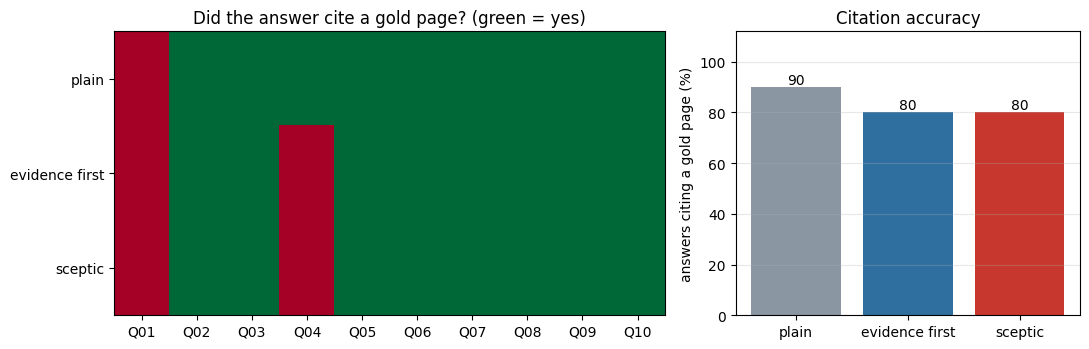

In [24]:
PLOT = {"plain": "#8A97A3", "evidence_first": "#2F6F9F", "sceptic": "#C8372D"}
cited = benched["answers"].pivot(index="arm", columns="qid", values="cited_gold").loc[list(ARMS)].drop(columns="Q11").astype(float)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
left.imshow(cited.to_numpy(), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
left.set(xticks=range(cited.shape[1]), xticklabels=cited.columns, yticks=range(3), title="Did the answer cite a gold page? (green = yes)")
left.set_yticklabels([a.replace("_", " ") for a in cited.index])
bars = right.bar([a.replace("_", " ") for a in compare.index], compare.cited_gold * 100, color=[PLOT[a] for a in compare.index])
right.bar_label(bars, fmt="%.0f")
right.set(ylim=(0, 112), ylabel="answers citing a gold page (%)", title="Citation accuracy")
right.grid(axis="y", alpha=.3)
fig.tight_layout()
fig.savefig(OUT / "extension.png", dpi=300, facecolor="white")
plt.show()

**Dashboard.** The briefing, indicators, trends and model checks on one page.

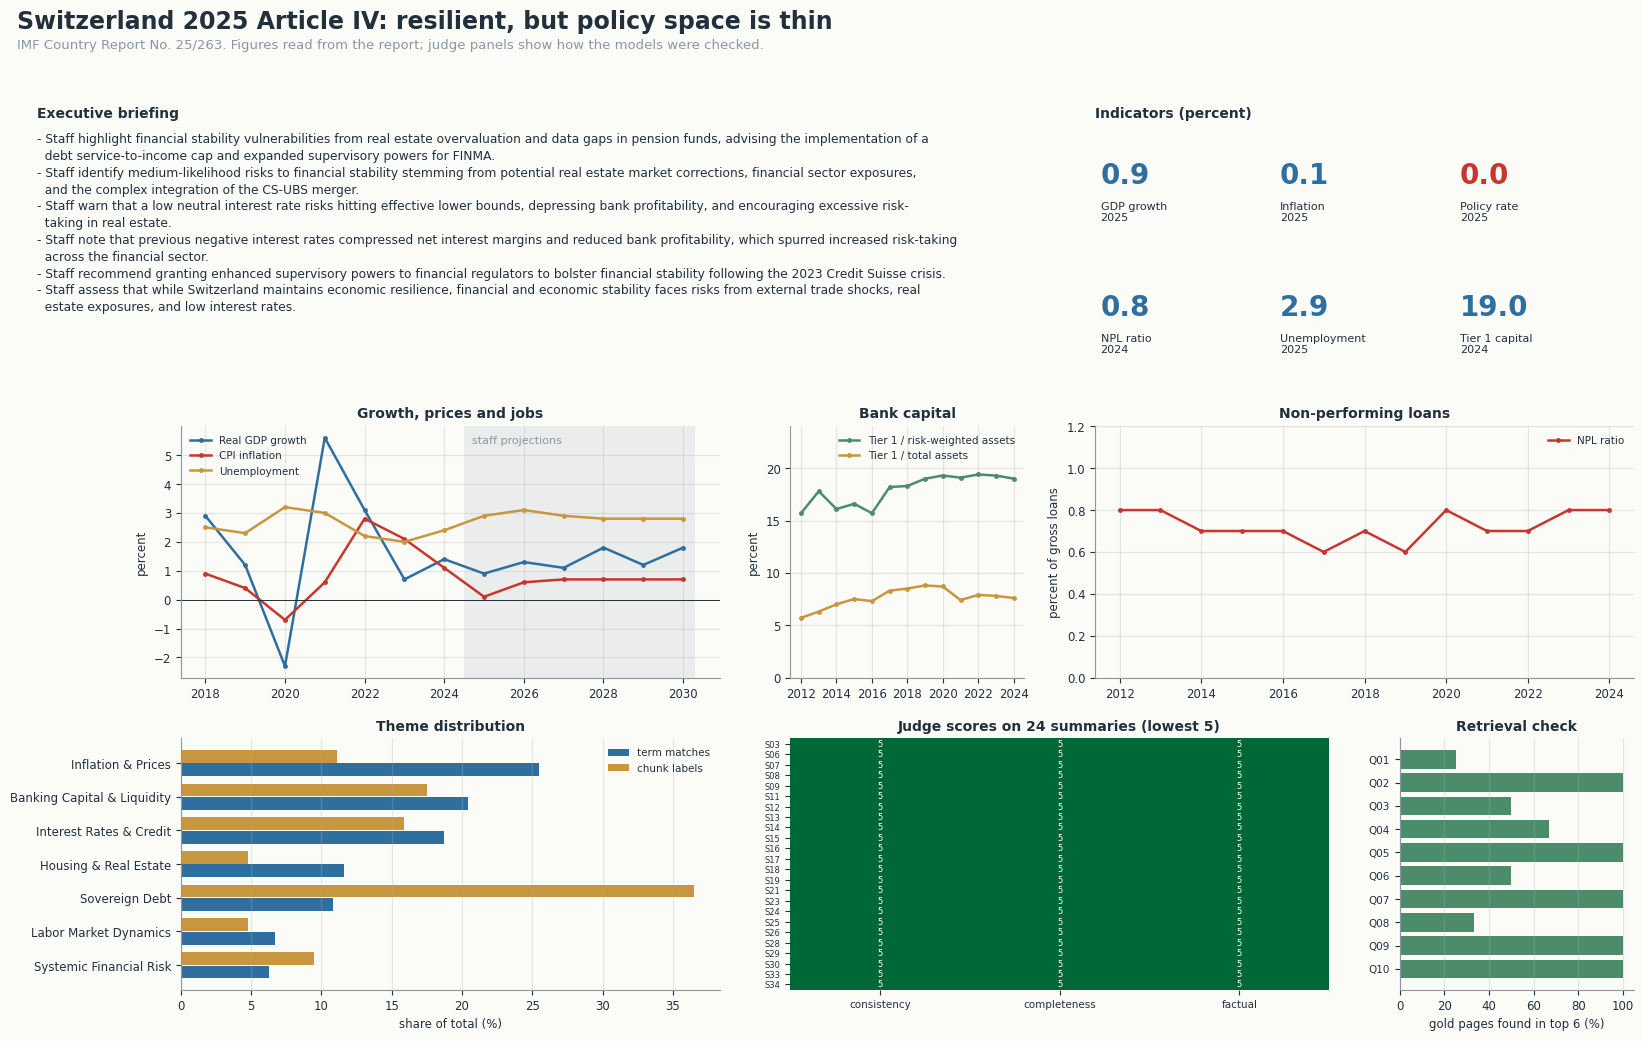

In [25]:
INK, RED, BLUE, GREEN, OCHRE, GREY, PAPER = "#22303C", "#C8372D", "#2F6F9F", "#4C8C6B", "#C8963E", "#8A97A3", "#FBFBF8"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5, "axes.titleweight": "bold", "axes.titlesize": 10, "axes.edgecolor": GREY, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False, "axes.facecolor": PAPER, "figure.facecolor": PAPER})
TILES = {"gdp_growth_forecast_pct": "GDP growth", "headline_inflation_rate_pct": "Inflation", "central_bank_policy_rate_pct": "Policy rate", "non_performing_loan_ratio": "NPL ratio", "unemployment_rate_pct": "Unemployment", "tier_1_capital_ratio": "Tier 1 capital"}
macro, banks = make("tables")["macro"], make("tables")["banks"]


def long_rows(table, chosen):
    years = [y for y in table.columns if isinstance(y, int)]
    return table.loc[list(chosen), years].rename(index=chosen).rename_axis("series").reset_index().melt(id_vars="series", var_name="year", value_name="pct").dropna().astype({"year": int, "pct": float})


def lines(ax, frame, colours):
    for name, part in frame.groupby("series", sort=False):
        ax.plot(part.year, part.pct, color=colours[name], lw=1.8, marker="o", ms=2.5, label=name)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=.3)
    ax.legend(frameon=False, fontsize=7.5, loc="best")


macro_long = long_rows(macro, {next(x for x in macro.index if x.startswith("Real GDP (Percent")): "Real GDP growth", next(x for x in macro.index if x.startswith("Consumer price index (period")): "CPI inflation", "Unemployment rate (in percent)": "Unemployment"})
bank_long = long_rows(banks, {next(x for x in banks.index if x.startswith("Regulatory Tier I capital as percent of risk")): "Tier 1 / risk-weighted assets", next(x for x in banks.index if x.startswith("Regulatory Tier 1 capital as percent of assets")): "Tier 1 / total assets"})
npl_long = long_rows(banks, {"Non-performing loans as percent of gross loans": "NPL ratio"})

fig, ax = plt.subplot_mosaic("BBBII;MMCNN;TTSSR", figsize=(16.5, 10.5), height_ratios=[1.05, 1.1, 1.1])
fig.suptitle("Switzerland 2025 Article IV: resilient, but policy space is thin", fontsize=17, fontweight="bold", x=.012, ha="left", y=.985)
fig.text(.012, .948, "IMF Country Report No. 25/263. Figures read from the report; judge panels show how the models were checked.", color=GREY, fontsize=9.5)

ax["B"].axis("off")
ax["B"].set_title("Executive briefing", loc="left", x=-.17)
text = "\n".join("\n".join(textwrap.wrap(b["sentence"], 150, initial_indent="- ", subsequent_indent="  ")) for b in brief["bullets"][:6])
ax["B"].text(-.17, .97, text, va="top", fontsize=8.8, linespacing=1.38, transform=ax["B"].transAxes)

ax["I"].axis("off")
ax["I"].set_title("Indicators (percent)", loc="left")
for i, (field, label) in enumerate(TILES.items()):
    x, y = (i % 3) / 3, .56 - (i // 3) * .55
    value = result["json"][field]
    ax["I"].text(x + .01, y + .2, "n/a" if value is None else f"{value:.1f}", fontsize=20, fontweight="bold", color=RED if field == "central_bank_policy_rate_pct" else BLUE, transform=ax["I"].transAxes)
    ax["I"].text(x + .01, y + .08, f"{label}\n{result['table'].set_index('field').year[field]}", fontsize=8, transform=ax["I"].transAxes, va="center")

lines(ax["M"], macro_long, {"Real GDP growth": BLUE, "CPI inflation": RED, "Unemployment": OCHRE})
ax["M"].axvspan(FLAGS.report_year - .5, macro_long.year.max() + .3, color=GREY, alpha=.14, lw=0)
ax["M"].text(FLAGS.report_year - .3, ax["M"].get_ylim()[1] * .9, "staff projections", color=GREY, fontsize=8)
ax["M"].axhline(0, color=INK, lw=.7)
ax["M"].set(title="Growth, prices and jobs", ylabel="percent")

lines(ax["C"], bank_long, {"Tier 1 / risk-weighted assets": GREEN, "Tier 1 / total assets": OCHRE})
ax["C"].set(title="Bank capital", ylabel="percent", ylim=(0, 24))
lines(ax["N"], npl_long, {"NPL ratio": RED})
ax["N"].set(title="Non-performing loans", ylabel="percent of gross loans", ylim=(0, 1.2))

shares = theme_result["table"].melt(id_vars="theme", value_vars=["term_share", "label_share"], var_name="count", value_name="share")
order = theme_result["table"].sort_values("term_share").theme.tolist()
for offset, (kind, colour, label) in zip((-.2, .2), (("term_share", BLUE, "term matches"), ("label_share", OCHRE, "chunk labels"))):
    part = shares[shares["count"] == kind].set_index("theme").loc[order]
    ax["T"].barh(np.arange(len(order)) + offset, part.share, height=.38, color=colour, label=label)
ax["T"].set(yticks=range(len(order)), yticklabels=order, xlabel="share of total (%)", title="Theme distribution")
ax["T"].legend(frameon=False, fontsize=7.5)
ax["T"].grid(axis="x", alpha=.3)

measures = ["consistency", "completeness", "factual_alignment"]
grid = board[measures].to_numpy(dtype=float)
ax["S"].imshow(grid, aspect="auto", cmap="RdYlGn", vmin=1, vmax=5)
ax["S"].set(xticks=range(3), yticks=range(len(board)), yticklabels=board.sid, title=f"Judge scores on {len(board)} summaries (lowest {grid.min():.0f})")
ax["S"].set_xticklabels(["consistency", "completeness", "factual"], fontsize=7.5)
ax["S"].tick_params(axis="y", labelsize=6)
for (row, col), v in np.ndenumerate(grid):
    ax["S"].text(col, row, f"{v:.0f}", ha="center", va="center", fontsize=6, color="white")

ax["S"].spines[:].set_visible(False)
recall = rag.dropna(subset="gold_recall")
ax["R"].barh(recall.qid[::-1], recall.gold_recall[::-1] * 100, color=GREEN)
ax["R"].set(xlim=(0, 105), xlabel="gold pages found in top 6 (%)", title="Retrieval check")
ax["R"].tick_params(axis="y", labelsize=7.5)
ax["R"].grid(axis="x", alpha=.3)

fig.tight_layout(rect=(0, 0, 1, .94), h_pad=1.6, w_pad=1.6)
fig.savefig(OUT / "dashboard.png", dpi=300, facecolor=PAPER)
plt.show()

**Run record.** The call log and prompts, saved for inspection.

In [26]:
log = pd.DataFrame(CALLS)
save("call_log", {"writer": FLAGS.writer, "judge": FLAGS.judge, "calls": len(log), "live": int((log.source == "live").sum()), "from_vault": int((log.source == "vault").sum()),
                  "repairs": int(log.step.str.endswith("+repair").sum()), "rows": log})
save("prompt_book", {name: {"system": system, "template": template} for name, (system, template) in PROMPTS.items()})
save("instructions", ARMS)
print(f"{len(log)} calls: {int((log.source == 'live').sum())} live, {int((log.source == 'vault').sum())} from the vault, {int(log.step.str.endswith('+repair').sum())} repairs")
log.groupby(["role", "model"]).agg(calls=("step", "size"), mean_seconds=("seconds", "mean"), tokens_in=("tokens_in", "sum"), tokens_out=("tokens_out", "sum")).round(2)

160 calls: 0 live, 160 from the vault, 0 repairs


,,calls,mean_seconds,tokens_in,tokens_out
role,model,,,,
judge,gemini-3.5-flash,72,3.74,192030,7925
writer,gemini-3.6-flash,88,8.65,261636,17889
